<a href="https://colab.research.google.com/github/syifaymd/Pratikum-Analisis-Deret-Waktu/blob/main/Tugas_Kelompok_7_Minggu_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1><center> PENDUGAAN PARAMETER </center></h1>
KELOMPOK 7 :

1. Nur Jannah Tuasikal (M0501251002)
2. Rismawati Saputri (A2502251012)
3. Syifa Ul Qalbi YMD (M0501251026)
4. Estyaningsi Purnama (M0501251058)

<center>
___________________________________________________________________________________________
</center>


<h1> TUGAS KELOMPOK </h1>
1. Buatlah simulasi deret waktu (parameter yang digunakan bebas, tetapi berbeda dengan contoh yag sudah digunakan di atas) menggunakan seed 25xx, dimana xx adalah jumlah dua digit terakhir NIM anggota kelompok (misal NIM: 09 dan 28, maka seed yang digunakan 2537 . Lakukan pendugaan parameter menggunakan metode Kuadrat Terkecil dan Kemungkinan Maksimum:

Kelompok 7: ARIMA (0,0,2) dan ARIMA (1,2,2)

<rjust> 2. Ulangi langkah no.1 sebanyak 30 ulangan. Hitunglah bias dan ragam dari penduga parameter menggunakan metode Kuadrat Terkecil dan Kemungkinan Maksimum yang diperoleh dari 30 ulangan tersebut. Dan buatlah boxplot untuk memvisualisasikan bias dan ragam tersebut. Interpretasikan boxpot yang diperoleh </rjust>

# Persiapan

In [ ]:
!pip install rpy2

In [ ]:
import warnings
warnings.filterwarnings("ignore")

#Jalankan syntax ini cukup satu kali, jangan berulang
%load_ext rpy2.ipython

In [ ]:
%%R
install.packages('TSA')

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
also installing the dependencies ‘xts’, ‘TTR’, ‘quadprog’, ‘zoo’, ‘quantmod’, ‘leaps’, ‘locfit’, ‘tseries’

trying URL 'https://cran.rstudio.com/src/contrib/xts_0.14.3.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/TTR_0.24.4.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/quadprog_1.5-8.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/zoo_1.9-1.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/quantmod_0.4.29.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/leaps_3.2.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/locfit_1.5-9.12.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/tseries_0.10-63.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/TSA_1.3.1.tar.gz'

The downloaded source packages are in
	‘/tmp/RtmpeMHLlB/downloaded_packages’


In [ ]:
%%R
library(TSA)


Attaching package: ‘TSA’

The following objects are masked from ‘package:stats’:

    acf, arima

The following object is masked from ‘package:utils’:

    tar



Untuk ilustrasi pendugaan parameter menggunakan metode momen dibangkitkan beberapa data simulasi dari model ARIMA (0,0,2) dan ARIMA (1,2,2).

In [ ]:
%%R

set.seed(2598)

# Simulasi ARIMA (0,0,2)
ma2 <- arima.sim(
  list(order = c(0,0,2),
       ma = c(0.4,-0.2)),
  n = 100
)

# Simulasi ARIMA (1,2,2)
# Bangkitkan ARMA(1,2), kemudian integrasikan dua kali
z <- arima.sim(
  list(order = c(1,0,2),
       ar = 0.4,
       ma = c(0.3,-0.2)),
  n = 100
)

arma122 <- cumsum(cumsum(as.numeric(z)))

# Menampilkan hasil simulasi
head(ma2)
head(arma122)


[1]  -0.7713949  -1.8760529  -4.3332709  -8.5458099 -15.8679703 -25.7793712


Untuk model *Autoregressive* penduga momen dari parameter model dapat dihitung menggunakan persamaan Yule-Walker, dengan $\rho_1$ disamadengankan $r_1$, $\rho_2$ disamadengankan $r_2$, dan seterusnya.

<center>$\phi_1+r_1\phi_2+r_2\phi_3+...+r_{p-1}\phi_p=r_1$</center>
<center>$r_1\phi_1+\phi_2+r_1\phi_3+...+r_{p-2}\phi_p=r_2$</center>
<center>$r_{p-1}\phi_1+r_{p-2}\phi_2+r_{p-3}\phi_3+...+\phi_p=r_p$</center>

Untuk model AR (1) penduga momen parameter adalah $\hat{\phi}=r_1$, sementara untuk model AR (2) penduga momen parameter adalah $\hat{\phi_1}=\frac{r_1(1-r_2)}{1-r_1^2}$ dan $\hat{\phi_2}=\frac{r_2-r_1^2}{1-r_1^2}$


Sementara untuk model MA (1), penduga momen dari parameter model **ada jika $|r_1|\le 0.5$**.

<center>$\hat{\theta}=\frac{-1+\sqrt{1-4r_1^2}}{2r_1}$</center>

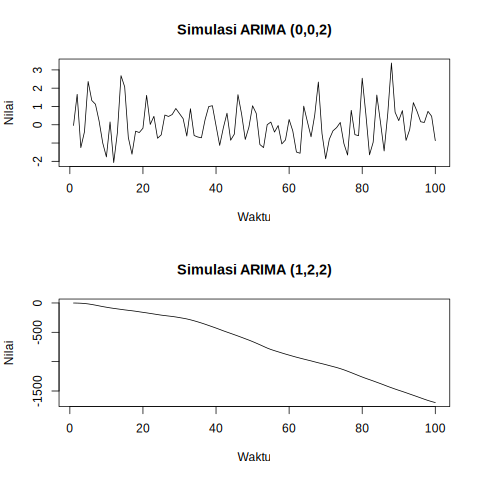

In [ ]:
%%R

par(mfrow = c(2,1))

plot(ma2, type = "l",
     main = "Simulasi ARIMA (0,0,2)",
     xlab = "Waktu", ylab = "Nilai")

plot(arma122, type = "l",
     main = "Simulasi ARIMA (1,2,2)",
     xlab = "Waktu", ylab = "Nilai")

par(mfrow = c(1,1))

<h1> Metode Kuadrat Terkecil</h1>

Perhatikan model AR(1):

<center>$Y_t-\mu=\phi(Y_{t-1}-\mu)+e_t$</center>

Penduga kuadrat terkecil diperoleh dengan meminimalkan kuadrat dari jumlahan $(Y_t-\mu)-(\phi(Y_{t-1}-\mu)$, atau dapat dituliskan sebagai:

<center>$SSE=\sum_{i=1}^n [(Y_t-\mu)-(\phi(Y_{t-1}-\mu)]^2$</center>

Parameter 𝜙 dan 𝜇 diduga dengan nilai yang meminimalkan $SSE$ jika diberikan $𝑌_1, 𝑌_1, … , 𝑌_𝑛$. Bentuk ini dapat digeneralisasi untuk model AR(p). Penduga kuadrat terkecil dikenal juga dengan **penduga kuadrat terkecil bersyarat**.

Selanjutnya untuk model MA(1):

<center>$Y_t=e_t-\theta e_{t-1}$</center>

Jika kita perhatikan model di atas, mungkin tampak bahwa metode kudrat terkecil tidak bisa diaplikasikan pada model MA(1) tersebut. Ingat bahwa model MA (1) yang *invertible* dapat dinyatakan sebagai model autoregressive dengan order yang tidak berhingga:

<center>$Y_t=-\theta Y_{t-1}-\theta^2Y_{t-2}-\theta^3Y_{t-3}-...+e_t$</center>

Sehingga dengan cara yang sama dengan model AR di atas, penduga parameter dalam model MA dapat diduga dengan meminimalkan

<center>$SSE=\sum_{i=1}^n [Y_t+\theta Y_{t-1}+\theta^2Y_{t-2}+\theta^3Y_{t-3}+...]^2$</center>

Karena parameter dalam persamaan $SSE$ tersebut tidak linier, maka untuk meminimalkannya dapat dilakukan dengan optimisasi numerik (misalnya Newton Raphson).

<h1> Metode Kemungkinan Maksimum </h1>

Fungsi kemungkinan (*likelihood*) $𝐿$ didefinisikan sebagai fungsi kepekatan peluang bersama dari data yang diamati ($Y$). Fungsi likelihood merupakan fungsi atas parameter model yang tidak diketahui dan data yang teramati. Untuk model ARIMA, $𝐿$ merupakan fungsi atas $\phi,\theta,\mu$ dan $\sigma_e^2$ jika pengamatan $𝑌_1, 𝑌_2, … , 𝑌_𝑛$ diketahui. Penduga kemungkinan maksimum selanjutnya didefinisikan sebagai nilai-nilai parameter yang memaksimumkan fungsi likelihood.

In [ ]:
%%R
set.seed(2598)

# Simulasi data ARIMA(0,0,2)
ar1_1 <- arima.sim(
  model = list(order = c(0,0,2), ma = c(0.4,-0.2)),
  n = 100
)

# Pendugaan parameter dengan CSS
print(arima(ar1_1, order = c(0,0,2), method = "CSS"))

# Pendugaan parameter dengan ML
print(arima(ar1_1, order = c(0,0,2), method = "ML"))



Call:
arima(x = ar1_1, order = c(0, 0, 2), method = "CSS")

Coefficients:
         ma1      ma2  intercept
      0.2589  -0.3389     0.0366
s.e.  0.1002   0.0955     0.0878

sigma^2 estimated as 0.9041:  part log likelihood = -136.85

Call:
arima(x = ar1_1, order = c(0, 0, 2), method = "ML")

Coefficients:
         ma1      ma2  intercept
      0.2622  -0.3376     0.0377
s.e.  0.1006   0.0943     0.0880

sigma^2 estimated as 0.8974:  log likelihood = -136.69,  aic = 279.38


- Untuk data simulasi MA (1) yang pertama, nilai parameter aslinya adalah 0.9. Hasil penduga momennya bernilai $NA$. Hal ini disebabkan karena nilai $|r_1|>0.5$, yaitu sebesar $-0.6205$
- Untuk data simulasi MA (1) yang kedua, nilai parameter aslinya adalah -0.9. Hasil penduga momennya bernilai $-0.6841$
- Untuk data simulasi MA (1) yang ketiga, nilai parameter aslinya adalah 0.5. Hasil penduga momennya bernilai $0.3926$
- Untuk data simulasi MA (1) yang keempat, nilai parameter aslinya adalah -0.5. Hasil penduga momennya bernilai $-0.3476$

Berdasarkan hasil ilustrasi di atas terlihat bahwa metode momen tidak begitu cocok diaplikasikan terhadap model *moving average*.

- Untuk data simulasi AR (1) yang pertama, nilai parameter aslinya adalah 0.9. Hasil penduga momennya bernilai $0.8121$
- Untuk data simulasi AR (1) yang kedua, nilai parameter aslinya adalah -0.4. Hasil penduga momennya bernilai $-0.4712$
- Untuk data simulasi AR (2) yang pertama, nilai parameter aslinya adalah 1.5 dan -0.75. Hasil penduga momennya bernilai $1.5370$ dan $-0.7633$
- Untuk data simulasi AR (2) yang kedua, nilai parameter aslinya adalah -0.25 dan 0.5. Hasil penduga momennya bernilai $-0.2715$ dan $0.4787$

- Untuk data simulasi AR (1) yang pertama, nilai parameter aslinya adalah 0.9. Hasil penduga kuadrat terkecilnya bernilai $0.8582$
- Untuk data simulasi AR (1) yang kedua, nilai parameter aslinya adalah -0.4. Hasil penduga kuadrat terkecilnya bernilai $-0.4872$
- Untuk data simulasi AR (2) yang pertama, nilai parameter aslinya adalah 1.5 dan -0.75. Hasil penduga kuadrat terkecilnya bernilai $1.5505$ dan $-0.7755$
- Untuk data simulasi AR (2) yang kedua, nilai parameter aslinya adalah -0.25 dan 0.5. Hasil penduga kuadrat terkecilnya bernilai $-0.2719$ dan $0.4788$

In [ ]:
%%R
set.seed(2598)

# Simulasi data untuk ARIMA(1,2,2)
z <- arima.sim(
  model = list(order = c(1,0,2), ar = 0.4, ma = c(0.3,-0.2)),
  n = 100
)

ar2_2 <- cumsum(cumsum(as.numeric(z)))

# Pendugaan parameter dengan CSS
print(arima(ar2_2, order = c(1,2,2),
            method = "CSS", transform.pars = FALSE))

# Pendugaan parameter dengan ML
print(arima(ar2_2, order = c(1,2,2),
            method = "ML", transform.pars = FALSE))



Call:
arima(x = ar2_2, order = c(1, 2, 2), transform.pars = FALSE, method = "CSS")

Coefficients:
         ar1      ma1      ma2
      0.6424  -0.0207  -0.4837
s.e.  0.3671   0.3513   0.2333

sigma^2 estimated as 0.8485:  part log likelihood = -131.01

Call:
arima(x = ar2_2, order = c(1, 2, 2), transform.pars = FALSE, method = "ML")

Coefficients:
         ar1      ma1      ma2
      0.9383  -0.3201  -0.6799
s.e.  0.0410   0.0865   0.0749

sigma^2 estimated as 0.8146:  log likelihood = -130.01,  aic = 266.01


- Untuk data simulasi MA (1) yang pertama, nilai parameter aslinya adalah 0.9. Hasil penduga kuadrat terkecilnya bernilai $0.9373$.
- Untuk data simulasi MA (1) yang kedua, nilai parameter aslinya adalah -0.9. Hasil penduga kuadrat terkecilnya bernilai $-0.9555$

In [ ]:
%%R

set.seed(2598)

B <- 30
n <- 100

cat("Kelompok: 7\n")
cat("Seed:", 2598, "\n")
cat("Jumlah replikasi:", B, "\n")
cat("Jumlah observasi per simulasi:", n, "\n")


Kelompok: 7
Seed: 2598 
Jumlah replikasi: 30 
Jumlah observasi per simulasi: 100 


In [ ]:
%%R

hasil <- data.frame()

for (b in 1:B) {

  # ====================================
  # MODEL 1: ARIMA (0,0,2)
  # ====================================

  y1 <- arima.sim(
    model = list(
      order = c(0,0,2),
      ma = c(0.4,-0.2)
    ),
    n = n
  )

  # ====================================
  # MODEL 2: ARIMA (1,2,2)
  # ====================================

  z <- arima.sim(
    model = list(
      order = c(1,0,2),
      ar = 0.4,
      ma = c(0.3,-0.2)
    ),
    n = n
  )

  y2 <- cumsum(cumsum(as.numeric(z)))

  # ====================================
  # ESTIMASI KEDUA MODEL
  # ====================================

  for (model in c("ARIMA(0,0,2)", "ARIMA(1,2,2)")) {

    if (model == "ARIMA(0,0,2)") {
      y <- y1
      orde <- c(0,0,2)
      nilai_benar <- c(ma1 = 0.4, ma2 = -0.2)
    } else {
      y <- y2
      orde <- c(1,2,2)
      nilai_benar <- c(ar1 = 0.4, ma1 = 0.3, ma2 = -0.2)
    }

    for (metode in c("CSS", "ML")) {

      fit <- tryCatch(
        suppressWarnings(
          arima(
            y,
            order = orde,
            method = metode,
            transform.pars = FALSE
          )
        ),
        error = function(e) NULL
      )

      if (!is.null(fit)) {

        koef <- fit$coef

        for (p in names(nilai_benar)) {

          if (p %in% names(koef)) {

            hasil <- rbind(
              hasil,
              data.frame(
                Replikasi = b,
                Model = model,
                Metode = metode,
                Parameter = p,
                Nilai_Benar = unname(nilai_benar[p]),
                Estimasi = unname(koef[p])
              )
            )
          }
        }
      }
    }
  }
}

cat("Jumlah baris estimasi yang berhasil:",
    nrow(hasil), "\n")

head(hasil, 10)

Jumlah baris estimasi yang berhasil: 300 
   Replikasi        Model Metode Parameter Nilai_Benar     Estimasi
1          1 ARIMA(0,0,2)    CSS       ma1         0.4  0.258861857
2          1 ARIMA(0,0,2)    CSS       ma2        -0.2 -0.338854178
3          1 ARIMA(0,0,2)     ML       ma1         0.4  0.262192949
4          1 ARIMA(0,0,2)     ML       ma2        -0.2 -0.337638236
5          1 ARIMA(1,2,2)    CSS       ar1         0.4  0.774842379
6          1 ARIMA(1,2,2)    CSS       ma1         0.3 -0.004489022
7          1 ARIMA(1,2,2)    CSS       ma2        -0.2 -0.465133866
8          1 ARIMA(1,2,2)     ML       ar1         0.4  0.675739220
9          1 ARIMA(1,2,2)     ML       ma1         0.3  0.128789338
10         1 ARIMA(1,2,2)     ML       ma2        -0.2 -0.344342784


In [ ]:
%%R

# Memisahkan data berdasarkan model, metode,
# dan parameter yang diestimasi

kelompok <- split(
  hasil,
  interaction(
    hasil$Model,
    hasil$Metode,
    hasil$Parameter,
    drop = TRUE
  )
)

ringkasan <- do.call(
  rbind,
  lapply(kelompok, function(d) {

    data.frame(
      Model = d$Model[1],
      Metode = d$Metode[1],
      Parameter = d$Parameter[1],
      Jumlah_Estimasi = nrow(d),
      Rata_rata = mean(d$Estimasi),
      Bias = mean(d$Estimasi - d$Nilai_Benar),
      Ragam = var(d$Estimasi)
    )
  })
)

rownames(ringkasan) <- NULL

print(ringkasan)


          Model Metode Parameter Jumlah_Estimasi   Rata_rata         Bias
1  ARIMA(1,2,2)    CSS       ar1              30  0.36735461 -0.032645385
2  ARIMA(1,2,2)     ML       ar1              30  0.19391703 -0.206082972
3  ARIMA(0,0,2)    CSS       ma1              30  0.38767625 -0.012323754
4  ARIMA(1,2,2)    CSS       ma1              30  0.33585853  0.035858525
5  ARIMA(0,0,2)     ML       ma1              30  0.45414328  0.054143276
6  ARIMA(1,2,2)     ML       ma1              30  0.53198514  0.231985137
7  ARIMA(0,0,2)    CSS       ma2              30 -0.20540450 -0.005404497
8  ARIMA(1,2,2)    CSS       ma2              30 -0.20420549 -0.004205488
9  ARIMA(0,0,2)     ML       ma2              30 -0.22969218 -0.029692177
10 ARIMA(1,2,2)     ML       ma2              30 -0.07345811  0.126541887
        Ragam
1  0.23045445
2  0.36926020
3  0.01274630
4  0.23699642
5  0.04367940
6  0.39972199
7  0.01954849
8  0.11938400
9  0.02886984
10 0.20716422


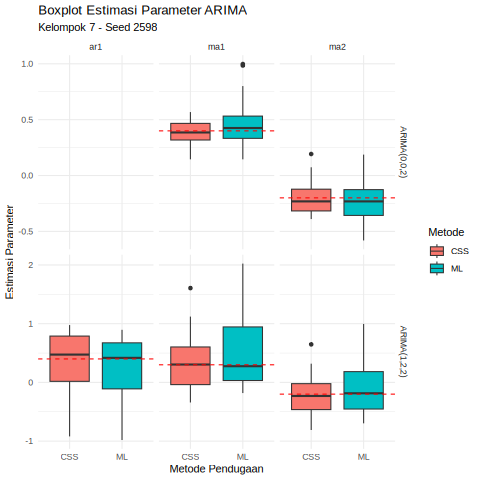

In [ ]:
%%R

# Memeriksa package ggplot2
if (!requireNamespace("ggplot2", quietly = TRUE)) {
  install.packages("ggplot2")
}

library(ggplot2)

ggplot(
  hasil,
  aes(x = Metode, y = Estimasi, fill = Metode)
) +
  geom_boxplot() +
  geom_hline(
    aes(yintercept = Nilai_Benar),
    color = "red",
    linetype = "dashed"
  ) +
  facet_grid(
    Model ~ Parameter,
    scales = "free_y"
  ) +
  labs(
    title = "Boxplot Estimasi Parameter ARIMA",
    subtitle = "Kelompok 7 - Seed 2598",
    x = "Metode Pendugaan",
    y = "Estimasi Parameter"
  ) +
  theme_minimal()


- Untuk data simulasi AR (1) yang pertama, nilai parameter aslinya adalah 0.9. Hasil penduga kemungkinan maksimumnya bernilai $0.8422$
- Untuk data simulasi AR (1) yang kedua, nilai parameter aslinya adalah -0.4. Hasil penduga kemungkinan maksimumnya bernilai $-0.4894$
- Untuk data simulasi AR (2) yang pertama, nilai parameter aslinya adalah 1.5 dan -0.75. Hasil penduga kemungkinan maksimumnya bernilai $1.5574$ dan $-0.7840$
- Untuk data simulasi AR (2) yang kedua, nilai parameter aslinya adalah -0.25 dan 0.5. Hasil penduga kemungkinan maksimumnya bernilai $-0.2694$ dan $0.4726$

<center><font size='4'> TERIMAKASIH </font></center><center>_Kelompok 7_ </center>